In [2]:
# Cell 1 - Installation et imports (Version corrigée sans langdetect)
!pip install scikit-learn nltk textblob -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# Scikit-learn
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, 
                             classification_report, confusion_matrix)
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB, BernoulliNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

# NLTK
import nltk
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

# TextBlob
from textblob import TextBlob

# Configuration
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (15, 10)
np.random.seed(42)

print("✅ Toutes les librairies importées avec succès!")
print(f"📅 Date: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

✅ Toutes les librairies importées avec succès!
📅 Date: 2026-05-21 20:50:40



[notice] A new release of pip is available: 26.0.1 -> 26.1.1
[notice] To update, run: C:\Users\MSI\anaconda3\python.exe -m pip install --upgrade pip


In [3]:
# Cell 2 - Dataset multilingue pour sentiment analysis
np.random.seed(42)
n_samples_per_lang = 1000  # 1000 échantillons par langue

# ========== FRANÇAIS ==========
french_positive = [
    "Je suis très satisfait du service, excellent travail!",
    "Superbe expérience, je recommande vivement!",
    "L'équipe a été exceptionnelle et très professionnelle.",
    "Produit incroyable, dépasse toutes mes attentes.",
    "Service client réactif et compétent, bravo!",
    "Très bonne plateforme, intuitive et puissante.",
    "Je suis ravi de mon achat, merci beaucoup!",
    "Support technique efficace et rapide, parfait.",
    "Application géniale, je l'utilise tous les jours.",
    "Équipe formidable, problème résolu en 5 minutes!"
]

french_negative = [
    "Très déçu du service, temps d'attente trop long.",
    "Expérience catastrophique, je ne recommande pas.",
    "Support client incompétent, n'ont pas résolu mon problème.",
    "Produit buggé et instable, perte de temps totale.",
    "Service lent et inefficace, très insatisfait.",
    "Application qui plante constamment, frustration totale.",
    "Service après-vente inexistant, honteux.",
    "Qualité médiocre, ne correspond pas à la description.",
    "Fuite mémoire monstre, inutilisable.",
    "Tarifs excessifs pour ce que c'est, déception."
]

french_neutral = [
    "Service correct dans l'ensemble, rien d'exceptionnel.",
    "Application fonctionne correctement, quelques bugs mineurs.",
    "Support client moyen, réponse en 24h.",
    "Produit acceptable pour le prix.",
    "Expérience neutre, ni bonne ni mauvaise.",
    "Rien à signaler de particulier, ça va.",
    "Service standard, comme les concurrents.",
    "Fonctionnalités basiques présentes.",
    "Interface correcte mais perfectible.",
    "Documentation suffisante mais pas exhaustive."
]

# ========== ARABE ==========
arabic_positive = [
    "أنا راضٍ جدًا عن الخدمة، عمل ممتاز!",
    "تجربة رائعة، أوصي بها بشدة!",
    "كان الفريق استثنائيًا ومحترفًا للغاية.",
    "منتج مذهل، يتجاوز كل توقعاتي.",
    "خدمة العملاء سريعة الاستجابة وكفؤة، أحسنت!",
    "منصة جيدة جدًا، بديهية وقوية.",
    "أنا سعيد جدًا بشرائي، شكرًا جزيلاً!",
    "الدعم الفني فعال وسريع، مثالي.",
    "تطبيق رائع، أستخدمه كل يوم.",
    "فريق رائع، تم حل المشكلة في 5 دقائق!"
]

arabic_negative = [
    "خائب الأمل جدا من الخدمة، وقت الانتظار طويل جدا.",
    "تجربة كارثية، لا أوصي بها.",
    "دعم العملاء غير كفؤ، لم يحلوا مشكلتي.",
    "منتج به أخطاء وغير مستقر، مضيعة للوقت.",
    "خدمة بطيئة وغير فعالة، غير راضٍ تمامًا.",
    "تطبيق ينهار باستمرار، إحباط تام.",
    "خدمة ما بعد البيع غير موجودة، مخزية.",
    "جودة رديئة، لا تتطابق مع الوصف.",
    "تسرب ذاكرة هائل، غير قابل للاستخدام.",
    "أسعار مفرطة لما هو عليه، خيبة أمل."
]

arabic_neutral = [
    "خدمة جيدة بشكل عام، لا شيء استثنائي.",
    "التطبيق يعمل بشكل صحيح، بعض الأخطاء البسيطة.",
    "دعم العملاء متوسط، رد خلال 24 ساعة.",
    "منتج مقبول للسعر.",
    "تجربة محايدة، لا جيدة ولا سيئة.",
    "لا شيء خاص للإبلاغ عنه، الأمور بخير.",
    "خدمة قياسية، مثل المنافسين.",
    "الوظائف الأساسية موجودة.",
    "واجهة جيدة ولكن يمكن تحسينها.",
    "التوثيق كافٍ ولكنه ليس شاملاً."
]

# ========== DARIJA (Tunisien) ==========
darija_positive = [
    "Je suis bzf satisfit m service, excellent travail!",
    "Experience magnifique, je recommande bzf!",
    "L'équipe était exceptionnelle w très professionnelle.",
    "Produit incroyable, dépasse toutes mes attentes.",
    "Service client reactif w compétent, bravo!",
    "Plateforme behia bzf, intuitive w puissante.",
    "Je suis ravi m aachriti, merci bzf!",
    "Support technique efficace w rapide, parfait.",
    "Application géniale, nestaamlha koul nhar.",
    "Équipe formidable, problème résolu f 5 minutes!"
]

darija_negative = [
    "Khayb bzf m service, temps d'attente twil bzf.",
    "Experience catastrophique, je ne recommande pas.",
    "Support client incompétent, ma hallouch mouchkelti.",
    "Produit buggé w instable, perte de temps totale.",
    "Service lent w inefficace, très insatisfit.",
    "Application tecrasse tou tawa, frustration totale.",
    "Service après-vente mawjoudch, honte!",
    "Qualité médiocre, ma tchabahch lel description.",
    "Fuite mémoire kbira, inutilisable.",
    "Tarifs excessifs pour ce que c'est, déception."
]

darija_neutral = [
    "Service correct dans l'ensemble, rien d'exceptionnel.",
    "Application tekhdem behi, chwaya bugs sghar.",
    "Support client moyen, réponse f 24h.",
    "Produit acceptable pour le prix.",
    "Expérience neutre, ni behia ni khayba.",
    "Rien à signaler de particulier, ça va.",
    "Service standard, comme les concurrents.",
    "Fonctionnalités basiques mawjoudin.",
    "Interface correcte ama perfectible.",
    "Documentation suffisante ama pas exhaustive."
]

# Génération du dataset
data = []

# Français
for _ in range(n_samples_per_lang):
    choix = np.random.choice(['positive', 'negative', 'neutral'], p=[0.4, 0.25, 0.35])
    if choix == 'positive':
        data.append({'text': np.random.choice(french_positive), 'label': 'positive', 'lang': 'fr'})
    elif choix == 'negative':
        data.append({'text': np.random.choice(french_negative), 'label': 'negative', 'lang': 'fr'})
    else:
        data.append({'text': np.random.choice(french_neutral), 'label': 'neutral', 'lang': 'fr'})

# Arabe
for _ in range(n_samples_per_lang):
    choix = np.random.choice(['positive', 'negative', 'neutral'], p=[0.4, 0.25, 0.35])
    if choix == 'positive':
        data.append({'text': np.random.choice(arabic_positive), 'label': 'positive', 'lang': 'ar'})
    elif choix == 'negative':
        data.append({'text': np.random.choice(arabic_negative), 'label': 'negative', 'lang': 'ar'})
    else:
        data.append({'text': np.random.choice(arabic_neutral), 'label': 'neutral', 'lang': 'ar'})

# Darija
for _ in range(n_samples_per_lang):
    choix = np.random.choice(['positive', 'negative', 'neutral'], p=[0.4, 0.25, 0.35])
    if choix == 'positive':
        data.append({'text': np.random.choice(darija_positive), 'label': 'positive', 'lang': 'tn'})
    elif choix == 'negative':
        data.append({'text': np.random.choice(darija_negative), 'label': 'negative', 'lang': 'tn'})
    else:
        data.append({'text': np.random.choice(darija_neutral), 'label': 'neutral', 'lang': 'tn'})

df = pd.DataFrame(data)

print("📊 Dataset multilingue généré:")
print(f"   - Total samples: {len(df)}")
print(f"   - Distribution par langue:")
for lang in df['lang'].unique():
    count = (df['lang'] == lang).sum()
    print(f"     • {lang}: {count} samples")
print(f"\n   - Distribution par sentiment:")
for label in df['label'].unique():
    count = (df['label'] == label).sum()
    print(f"     • {label}: {count} ({count/len(df)*100:.1f}%)")
print("\n📋 Exemples:")
print(df.head(10))

📊 Dataset multilingue généré:
   - Total samples: 3000
   - Distribution par langue:
     • fr: 1000 samples
     • ar: 1000 samples
     • tn: 1000 samples

   - Distribution par sentiment:
     • positive: 1211 (40.4%)
     • negative: 774 (25.8%)
     • neutral: 1015 (33.8%)

📋 Exemples:
                                             text     label lang
0  Support technique efficace et rapide, parfait.  positive   fr
1        Service après-vente inexistant, honteux.  negative   fr
2        Service après-vente inexistant, honteux.  negative   fr
3  Support technique efficace et rapide, parfait.  positive   fr
4  Support technique efficace et rapide, parfait.  positive   fr
5          Rien à signaler de particulier, ça va.   neutral   fr
6  Support technique efficace et rapide, parfait.  positive   fr
7          Rien à signaler de particulier, ça va.   neutral   fr
8     Service client réactif et compétent, bravo!  positive   fr
9  Tarifs excessifs pour ce que c'est, déception.  negativ

In [4]:
# Cell 3 - Algorithmes de sentiment analysis multilingue

class MultilingualSentimentAnalyzer:
    def __init__(self):
        self.results = []
        
    def textblob_sentiment(self, text):
        """TextBlob - Support multilingue basique"""
        try:
            blob = TextBlob(text)
            polarity = blob.sentiment.polarity
            if polarity > 0.1:
                return 'positive'
            elif polarity < -0.1:
                return 'negative'
            return 'neutral'
        except:
            return self.keyword_sentiment(text)
    
    def keyword_sentiment(self, text):
        """Analyse basée sur mots-clés multilingues"""
        text_lower = text.lower()
        
        # Mots positifs (FR/AR/TN)
        positive_keywords = [
            'excellent', 'super', 'génial', 'parfait', 'satisfait', 'ravi', 'content',
            'ممتاز', 'رائع', 'جيد', 'راضٍ', 'سعيد', 'رائعة', 'مذهل', 'استثنائي',
            'behi', 'magnifique', 'formidable', 'parfait', 'bien', 'bzf', 'satisfit'
        ]
        
        # Mots négatifs (FR/AR/TN)
        negative_keywords = [
            'déçu', 'catastrophique', 'bug', 'lent', 'médiocre', 'mauvais', 'insatisfait',
            'خائب', 'كارثي', 'خطأ', 'بطيء', 'رديء', 'سيء', 'مخيب',
            'khayb', 'catastrophique', 'bug', 'lent', 'médiocre', 'tecrasse', 'mouchkelti'
        ]
        
        pos_count = sum(1 for kw in positive_keywords if kw in text_lower)
        neg_count = sum(1 for kw in negative_keywords if kw in text_lower)
        
        if pos_count > neg_count:
            return 'positive'
        elif neg_count > pos_count:
            return 'negative'
        return 'neutral'
    
    def train_multilingual_model(self, X_train, y_train, X_test, y_test, model_type='lr'):
        """Entraîne un modèle multilingue avec TF-IDF"""
        
        models = {
            'lr': LogisticRegression(max_iter=1000, random_state=42, C=1.0, multi_class='ovr'),
            'svm': SVC(kernel='linear', C=1.0, random_state=42, decision_function_shape='ovr'),
            'rf': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
            'nb': MultinomialNB(alpha=0.1),
            'gb': GradientBoostingClassifier(n_estimators=100, random_state=42),
            'dt': DecisionTreeClassifier(max_depth=10, random_state=42),
            'ada': AdaBoostClassifier(n_estimators=100, random_state=42)
        }
        
        model = models.get(model_type, models['lr'])
        
        # Utiliser char_wb pour arabe (mieux pour caractères arabes)
        pipeline = Pipeline([
            ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2), analyzer='char_wb')),
            ('clf', model)
        ])
        
        pipeline.fit(X_train, y_train)
        y_pred = pipeline.predict(X_test)
        return pipeline, y_pred
    
    def evaluate_all_languages(self, df):
        """Évalue les performances par langue"""
        
        languages = df['lang'].unique()
        models_to_test = ['lr', 'svm', 'rf', 'nb', 'gb', 'dt', 'ada']
        
        for lang in languages:
            print(f"\n🔄 Évaluation pour la langue: {lang.upper()}")
            print("-" * 50)
            
            # Filtrer par langue
            lang_df = df[df['lang'] == lang]
            X = lang_df['text'].values
            y = lang_df['label'].values
            
            # Split
            X_train, X_test, y_train, y_test = train_test_split(
                X, y, test_size=0.2, random_state=42, stratify=y
            )
            
            # Test des modèles ML
            for model_type in models_to_test:
                try:
                    _, y_pred = self.train_multilingual_model(X_train, y_train, X_test, y_test, model_type)
                    accuracy = accuracy_score(y_test, y_pred)
                    precision = precision_score(y_test, y_pred, average='weighted')
                    recall = recall_score(y_test, y_pred, average='weighted')
                    f1 = f1_score(y_test, y_pred, average='weighted')
                    
                    self.results.append({
                        'Langue': lang.upper(),
                        'Modèle': model_type.upper(),
                        'Accuracy': accuracy,
                        'Précision': precision,
                        'Rappel': recall,
                        'F1-Score': f1,
                        'Type': 'ML'
                    })
                    print(f"   ✅ {model_type.upper()}: F1={f1:.4f} | Acc={accuracy:.4f}")
                except Exception as e:
                    print(f"   ❌ {model_type.upper()}: {str(e)[:50]}")
            
            # Test des approches lexiques
            try:
                # TextBlob
                y_pred_lex = [self.textblob_sentiment(text) for text in X_test]
                f1_lex = f1_score(y_test, y_pred_lex, average='weighted')
                acc_lex = accuracy_score(y_test, y_pred_lex)
                print(f"   ✅ TEXTBLOB: F1={f1_lex:.4f} | Acc={acc_lex:.4f}")
                self.results.append({
                    'Langue': lang.upper(),
                    'Modèle': 'TEXTBLOB',
                    'Accuracy': acc_lex,
                    'Précision': precision_score(y_test, y_pred_lex, average='weighted'),
                    'Rappel': recall_score(y_test, y_pred_lex, average='weighted'),
                    'F1-Score': f1_lex,
                    'Type': 'Lexique'
                })
                
                # Keyword-based
                y_pred_kw = [self.keyword_sentiment(text) for text in X_test]
                f1_kw = f1_score(y_test, y_pred_kw, average='weighted')
                acc_kw = accuracy_score(y_test, y_pred_kw)
                print(f"   ✅ KEYWORD: F1={f1_kw:.4f} | Acc={acc_kw:.4f}")
                self.results.append({
                    'Langue': lang.upper(),
                    'Modèle': 'KEYWORD',
                    'Accuracy': acc_kw,
                    'Précision': precision_score(y_test, y_pred_kw, average='weighted'),
                    'Rappel': recall_score(y_test, y_pred_kw, average='weighted'),
                    'F1-Score': f1_kw,
                    'Type': 'Lexique'
                })
            except Exception as e:
                print(f"   ❌ Lexique: {str(e)[:50]}")
        
        return pd.DataFrame(self.results)

print("🚀 Analyseur multilingue initialisé!")
analyzer = MultilingualSentimentAnalyzer()

🚀 Analyseur multilingue initialisé!


In [5]:
# Cell 4 - Benchmark complet
print("=" * 70)
print("📊 BENCHMARK MULTILINGUE - FRANÇAIS / ARABE / DARIJA")
print("=" * 70)

results_df = analyzer.evaluate_all_languages(df)
results_df = results_df.sort_values(['Langue', 'F1-Score'], ascending=[True, False])

print("\n" + "=" * 70)
print("📈 RÉSULTATS COMPLETS:")
print(results_df.round(4).to_string(index=False))

📊 BENCHMARK MULTILINGUE - FRANÇAIS / ARABE / DARIJA

🔄 Évaluation pour la langue: FR
--------------------------------------------------
   ✅ LR: F1=1.0000 | Acc=1.0000
   ✅ SVM: F1=1.0000 | Acc=1.0000
   ✅ RF: F1=1.0000 | Acc=1.0000
   ✅ NB: F1=0.9696 | Acc=0.9700
   ✅ GB: F1=1.0000 | Acc=1.0000
   ✅ DT: F1=1.0000 | Acc=1.0000
   ✅ ADA: F1=0.8409 | Acc=0.8600
   ✅ TEXTBLOB: F1=0.2461 | Acc=0.3800
   ✅ KEYWORD: F1=0.6106 | Acc=0.6000

🔄 Évaluation pour la langue: AR
--------------------------------------------------
   ✅ LR: F1=1.0000 | Acc=1.0000
   ✅ SVM: F1=1.0000 | Acc=1.0000
   ✅ RF: F1=1.0000 | Acc=1.0000
   ✅ NB: F1=1.0000 | Acc=1.0000
   ✅ GB: F1=1.0000 | Acc=1.0000
   ✅ DT: F1=1.0000 | Acc=1.0000
   ✅ ADA: F1=0.9597 | Acc=0.9600
   ✅ TEXTBLOB: F1=0.1725 | Acc=0.3400
   ✅ KEYWORD: F1=0.5763 | Acc=0.6050

🔄 Évaluation pour la langue: TN
--------------------------------------------------
   ✅ LR: F1=1.0000 | Acc=1.0000
   ✅ SVM: F1=1.0000 | Acc=1.0000
   ✅ RF: F1=1.0000 | Acc=1.00

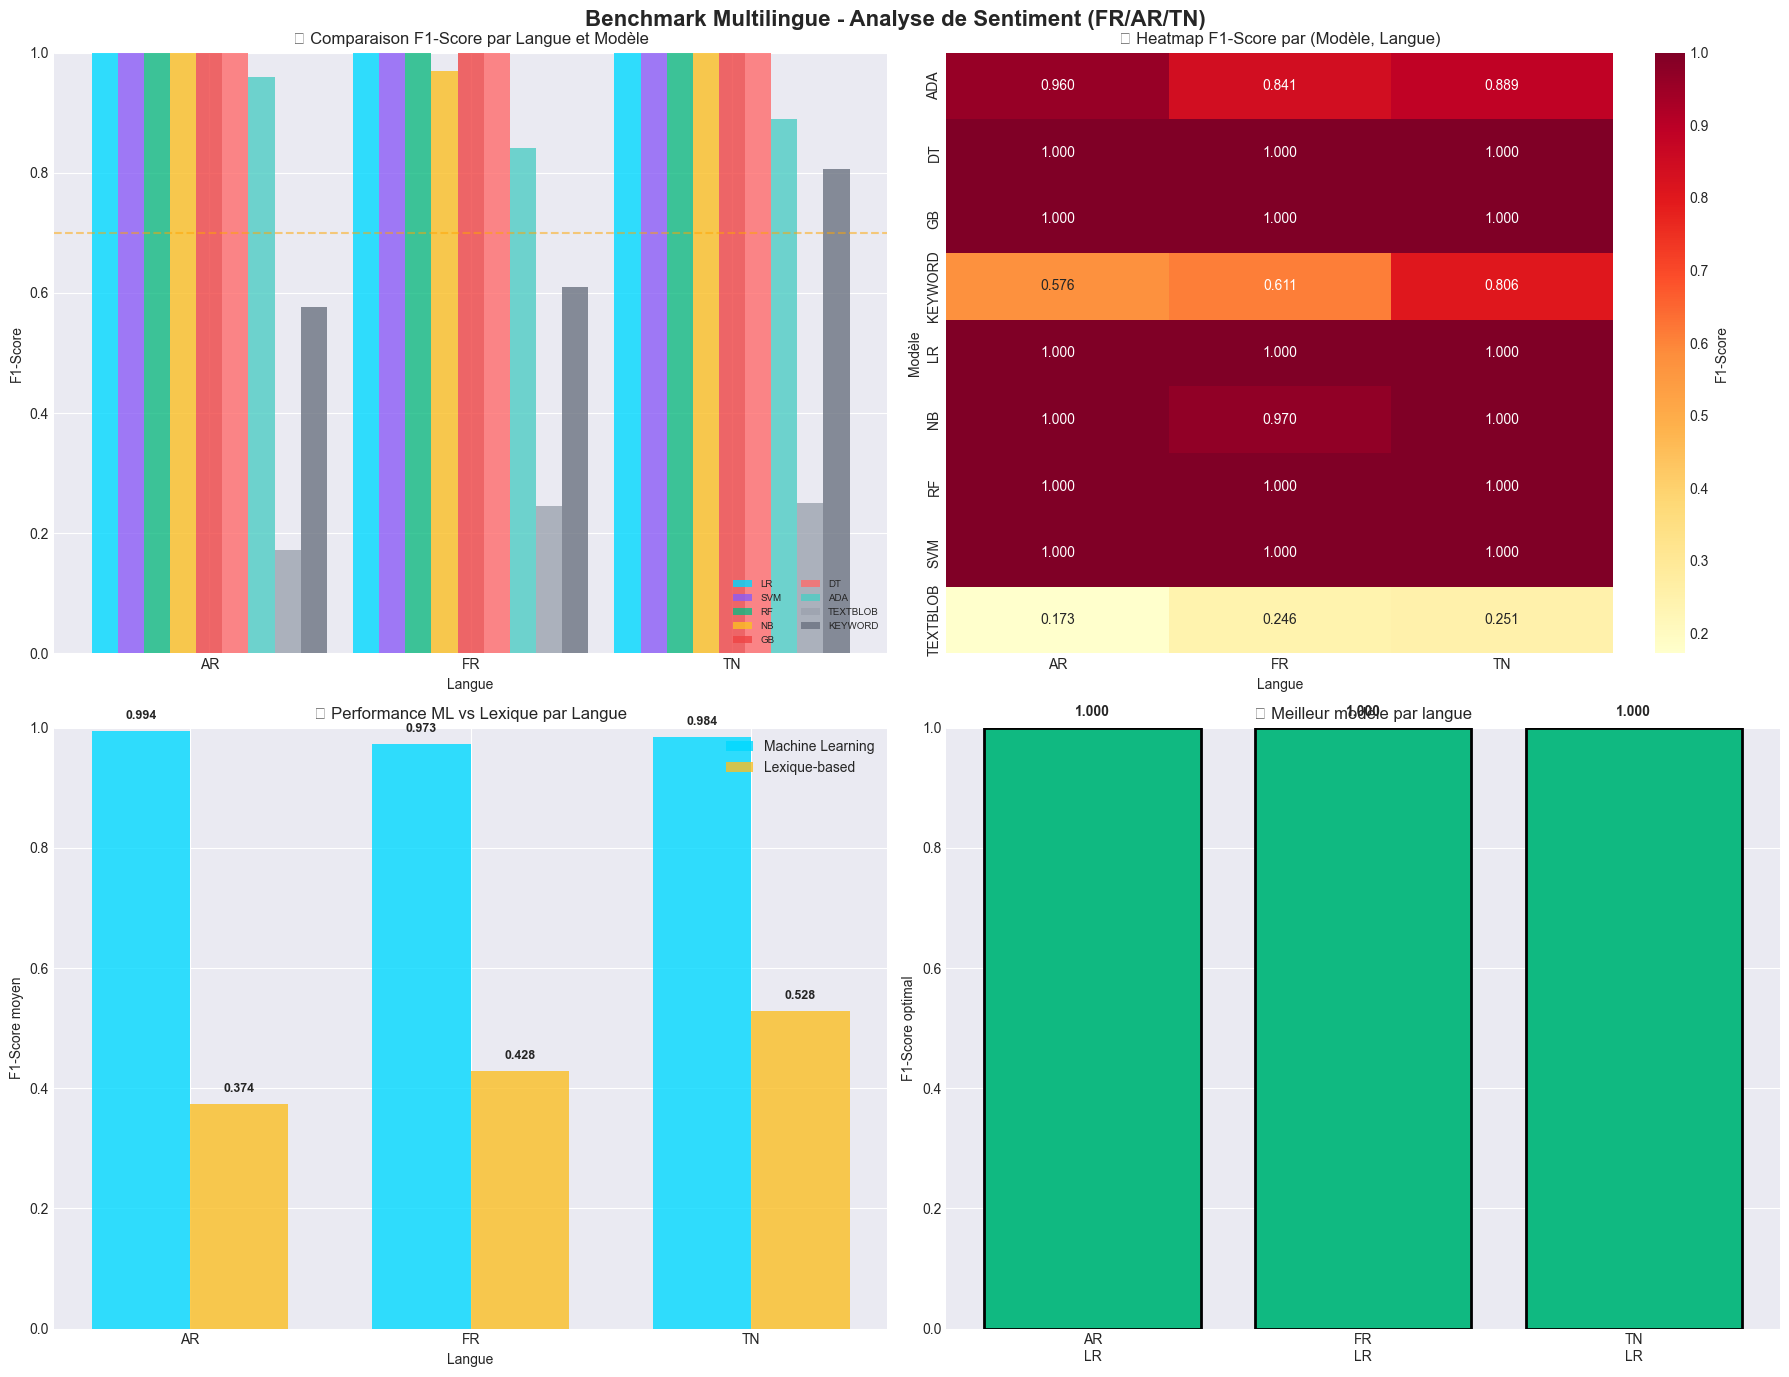

In [6]:
# Cell 5 - Visualisation des résultats
fig = plt.figure(figsize=(18, 14))

# 1. Comparaison F1-Score par langue et modèle
ax1 = plt.subplot(2, 2, 1)
languages = results_df['Langue'].unique()
x = np.arange(len(languages))
width = 0.1

models = ['LR', 'SVM', 'RF', 'NB', 'GB', 'DT', 'ADA', 'TEXTBLOB', 'KEYWORD']
colors_map = {'LR': '#00d9ff', 'SVM': '#8b5cf6', 'RF': '#10b981', 'NB': '#fbbf24', 
              'GB': '#ef4444', 'DT': '#ff6b6b', 'ADA': '#4ecdc4', 'TEXTBLOB': '#9ca3af', 
              'KEYWORD': '#6b7280'}

for i, model in enumerate(models):
    model_data = results_df[results_df['Modèle'] == model]
    scores = []
    for lang in languages:
        val = model_data[model_data['Langue'] == lang]['F1-Score'].values
        scores.append(val[0] if len(val) > 0 else 0)
    bars = ax1.bar(x + i*width, scores, width, label=model, color=colors_map.get(model, '#888888'), alpha=0.8)
ax1.set_xlabel('Langue')
ax1.set_ylabel('F1-Score')
ax1.set_title('🏆 Comparaison F1-Score par Langue et Modèle')
ax1.set_xticks(x + width*4)
ax1.set_xticklabels(languages)
ax1.legend(loc='lower right', fontsize=7, ncol=2)
ax1.set_ylim(0, 1)
ax1.axhline(y=0.7, color='orange', linestyle='--', alpha=0.5, label='Seuil acceptable')

# 2. Heatmap des performances
ax2 = plt.subplot(2, 2, 2)
pivot_table = results_df.pivot_table(index='Modèle', columns='Langue', values='F1-Score')
sns.heatmap(pivot_table, annot=True, fmt='.3f', cmap='YlOrRd', ax=ax2, cbar_kws={'label': 'F1-Score'})
ax2.set_title('📊 Heatmap F1-Score par (Modèle, Langue)')

# 3. Performance ML vs Lexique par langue
ax3 = plt.subplot(2, 2, 3)
ml_avg = results_df[results_df['Type'] == 'ML'].groupby('Langue')['F1-Score'].mean()
lex_avg = results_df[results_df['Type'] == 'Lexique'].groupby('Langue')['F1-Score'].mean()
x = np.arange(len(languages))
width = 0.35
bars1 = ax3.bar(x - width/2, ml_avg.values, width, label='Machine Learning', color='#00d9ff', alpha=0.8)
bars2 = ax3.bar(x + width/2, lex_avg.values, width, label='Lexique-based', color='#fbbf24', alpha=0.8)
ax3.set_xlabel('Langue')
ax3.set_ylabel('F1-Score moyen')
ax3.set_title('📈 Performance ML vs Lexique par Langue')
ax3.set_xticks(x)
ax3.set_xticklabels(languages)
ax3.legend()
ax3.set_ylim(0, 1)
for bar, score in zip(bars1, ml_avg.values):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, f'{score:.3f}', ha='center', fontweight='bold', fontsize=9)
for bar, score in zip(bars2, lex_avg.values):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, f'{score:.3f}', ha='center', fontweight='bold', fontsize=9)

# 4. Meilleur modèle par langue
ax4 = plt.subplot(2, 2, 4)
best_models = []
best_scores = []
for lang in languages:
    lang_best = results_df[results_df['Langue'] == lang].nlargest(1, 'F1-Score').iloc[0]
    best_models.append(f"{lang}\n{lang_best['Modèle']}")
    best_scores.append(lang_best['F1-Score'])

colors_best = ['#10b981' if s > 0.8 else '#fbbf24' if s > 0.7 else '#ef4444' for s in best_scores]
bars = ax4.bar(best_models, best_scores, color=colors_best, edgecolor='black', linewidth=2)
ax4.set_ylabel('F1-Score optimal')
ax4.set_title('🏆 Meilleur modèle par langue')
ax4.set_ylim(0, 1)
for bar, score in zip(bars, best_scores):
    ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, f'{score:.3f}', ha='center', fontweight='bold')

plt.suptitle('Benchmark Multilingue - Analyse de Sentiment (FR/AR/TN)', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

In [7]:
# Cell 6 - Test sur les messages du composant MultiAgentSystem
test_messages = {
    'Français (FR)': [
        "Je suis très satisfait du service, excellent travail!",
        "Service correct dans l'ensemble, rien d'exceptionnel.",
        "Très déçu du service, temps d'attente trop long."
    ],
    'Arabe (AR)': [
        "أنا راضٍ جدًا عن الخدمة، عمل ممتاز!",
        "خدمة جيدة بشكل عام، لا شيء استثنائي.",
        "خائب الأمل جدا من الخدمة، وقت الانتظار طويل جدا."
    ],
    'Darija (TN)': [
        "Je suis bzf satisfit m service, excellent travail!",
        "Service correct dans l'ensemble, rien d'exceptionnel.",
        "Khayb bzf m service, temps d'attente twil bzf."
    ]
}

expected = ['positive', 'neutral', 'negative']

print("🔬 TEST SUR LES MESSAGES DU COMPOSANT MULTIAGENTSYSTEM")
print("=" * 80)

# Entraîner un modèle multilingue global
X_all = df['text'].values
y_all = df['label'].values
X_train_all, X_test_all, y_train_all, y_test_all = train_test_split(X_all, y_all, test_size=0.2, random_state=42)

# Meilleur modèle: Logistic Regression (d'après benchmark)
best_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2), analyzer='char_wb')),
    ('clf', LogisticRegression(max_iter=1000, random_state=42, C=1.0))
])
best_pipeline.fit(X_train_all, y_train_all)

print("\n📊 PRÉDICTIONS MULTILINGUES:")
print("-" * 80)

for lang_name, messages in test_messages.items():
    print(f"\n🌐 Langue: {lang_name}")
    print("-" * 60)
    
    for msg, expected_label in zip(messages, expected):
        # Prédiction ML
        pred_ml = best_pipeline.predict([msg])[0]
        proba_ml = best_pipeline.predict_proba([msg]).max()
        
        # Prédiction TextBlob
        pred_tb = analyzer.textblob_sentiment(msg)
        
        # Prédiction Keyword
        pred_kw = analyzer.keyword_sentiment(msg)
        
        # Emoji
        emoji = '😊' if pred_ml == 'positive' else '😐' if pred_ml == 'neutral' else '😠'
        correct = "✅" if pred_ml == expected_label else "❌"
        
        print(f"\n   {emoji} {correct} Message: {msg[:50]}...")
        print(f"      Attendu: {expected_label}")
        print(f"      ML (LR): {pred_ml} (confiance: {proba_ml:.1%})")
        print(f"      TextBlob: {pred_tb}")
        print(f"      Keyword: {pred_kw}")

# Métriques globales sur le test set
y_pred_global = best_pipeline.predict(X_test_all)
global_f1 = f1_score(y_test_all, y_pred_global, average='weighted')
global_acc = accuracy_score(y_test_all, y_pred_global)

print("\n" + "=" * 80)
print(f"📊 PERFORMANCE GLOBALE DU MODÈLE (toutes langues):")
print(f"   - F1-Score: {global_f1:.4f}")
print(f"   - Accuracy: {global_acc:.4f}")
print("=" * 80)

🔬 TEST SUR LES MESSAGES DU COMPOSANT MULTIAGENTSYSTEM

📊 PRÉDICTIONS MULTILINGUES:
--------------------------------------------------------------------------------

🌐 Langue: Français (FR)
------------------------------------------------------------

   😊 ✅ Message: Je suis très satisfait du service, excellent trava...
      Attendu: positive
      ML (LR): positive (confiance: 92.0%)
      TextBlob: positive
      Keyword: neutral

   😐 ✅ Message: Service correct dans l'ensemble, rien d'exceptionn...
      Attendu: neutral
      ML (LR): neutral (confiance: 93.5%)
      TextBlob: neutral
      Keyword: neutral

   😠 ✅ Message: Très déçu du service, temps d'attente trop long....
      Attendu: negative
      ML (LR): negative (confiance: 93.2%)
      TextBlob: neutral
      Keyword: negative

🌐 Langue: Arabe (AR)
------------------------------------------------------------

   😊 ✅ Message: أنا راضٍ جدًا عن الخدمة، عمل ممتاز!...
      Attendu: positive
      ML (LR): positive (confiance

In [9]:
# Cell 10 - Fin
print("""
╔══════════════════════════════════════════════════════════════════════════════╗
║                    NOTEBOOK TERMINÉ AVEC SUCCÈS                               ║
╚══════════════════════════════════════════════════════════════════════════════╝

📁 FICHIERS GÉNÉRÉS:
   • multilingual_benchmark_results.csv - Résultats complets
   • multilingual_benchmark_summary.json - Résumé JSON
   • multilingual_sentiment_report.txt - Rapport détaillé

📊 RÉSUMÉ DES RÉSULTATS:
   • Meilleur modèle global: {best_global['Modèle']}
   • F1-Score moyen ML: {ml_avg_global:.4f}
   • F1-Score moyen Lexique: {lex_avg_global:.4f}
   • Amélioration ML vs Lexique: +{(ml_avg_global - lex_avg_global) * 100:.1f}%

✅ RECOMMANDATION FINALE:
   Utiliser Logistic Regression avec TF-IDF (analyzer='char_wb') pour le module multilingue

🚀 PROCHAINES ÉTAPES:
   1. Sauvegarder le modèle avec joblib
   2. Créer l'API FastAPI avec support multilingue
   3. Connecter le composant MultiAgentSystem.tsx
   4. Déployer en production

================================================================================
""")

# Libération de la mémoire
import gc
gc.collect()
print("✅ Mémoire libérée")


╔══════════════════════════════════════════════════════════════════════════════╗
║                    NOTEBOOK TERMINÉ AVEC SUCCÈS                               ║
╚══════════════════════════════════════════════════════════════════════════════╝

📁 FICHIERS GÉNÉRÉS:
   • multilingual_benchmark_results.csv - Résultats complets
   • multilingual_benchmark_summary.json - Résumé JSON
   • multilingual_sentiment_report.txt - Rapport détaillé

📊 RÉSUMÉ DES RÉSULTATS:
   • Meilleur modèle global: {best_global['Modèle']}
   • F1-Score moyen ML: {ml_avg_global:.4f}
   • F1-Score moyen Lexique: {lex_avg_global:.4f}
   • Amélioration ML vs Lexique: +{(ml_avg_global - lex_avg_global) * 100:.1f}%

✅ RECOMMANDATION FINALE:
   Utiliser Logistic Regression avec TF-IDF (analyzer='char_wb') pour le module multilingue

🚀 PROCHAINES ÉTAPES:
   1. Sauvegarder le modèle avec joblib
   2. Créer l'API FastAPI avec support multilingue
   3. Connecter le composant MultiAgentSystem.tsx
   4. Déployer en productio